<a href="https://colab.research.google.com/github/fathimaajvad/NLP-Assignment/blob/main/Context_Aware_Sarcasm_Implicit_Sentiment_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Context-Aware Sarcasm and Implicit Sentiment Detection Using NLP

**NLP Assignment 2**

This notebook studies sarcasm detection and conventional sentiment classification as separate tasks. Sarcasm depends heavily on context; a model's sentiment label is not proof of a speaker's intended meaning.

## Objectives
- Inspect a real sarcasm-labelled dataset and document its schema.
- Train a TF–IDF + Logistic Regression baseline.
- Fine-tune DistilBERT when the runtime and model download are available; otherwise report the limitation explicitly.
- Train a separate conventional sentiment classifier.
- Compare models using held-out metrics and inspect errors.
- Provide a reusable prediction pipeline and optional Colab widgets.

**Reproducibility:** fixed random seed; stratified train/validation/test split; evaluation on held-out test data only. Do not interpret illustrative examples as benchmark results.

## 1. Environment setup

In [36]:
import os, sys, json, random, warnings, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.preprocessing import LabelEncoder
SEED = 42
random.seed(SEED); np.random.seed(SEED)
ROOT = Path('/content') if 'google.colab' in sys.modules else Path.cwd()
OUT = ROOT / 'assignment2_outputs'
FIG = OUT / 'figures'
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
print('Python:', sys.version.split()[0])
print('Output directory:', OUT.resolve())

Python: 3.13.15
Output directory: /content/assignment2_outputs


## 2. Dataset acquisition and schema verification
The default sarcasm dataset is the public News Headlines Dataset for Sarcasm Detection (JSON Lines). This cell downloads the published file only when internet access is available. It does not manufacture rows or statistics.

In [39]:
import urllib.request
from pathlib import Path
import pandas as pd
import sys
import json

if 'OUT' not in globals():
    ROOT = Path('/content') if 'google.colab' in sys.modules else Path.cwd()
    OUT = ROOT / 'assignment2_outputs'
    OUT.mkdir(parents=True, exist_ok=True)

DATA_URL = 'https://raw.githubusercontent.com/rishabhmisra/News-Headlines-Dataset-For-Sarcasm-Detection/master/Sarcasm_Headlines_Dataset.json'
DATA_PATH = OUT / 'Sarcasm_Headlines_Dataset.json'

print('Downloading or reading the dataset...')
try:
    if not DATA_PATH.exists():
        urllib.request.urlretrieve(DATA_URL, DATA_PATH)
except Exception as e:
    try:
        if not DATA_PATH.exists():
            PRIMARY_URL = 'https://rishabhmisra.in/articles/Sarcasm_Headlines_Dataset.json'
            urllib.request.urlretrieve(PRIMARY_URL, DATA_PATH)
    except Exception as err:
        if not DATA_PATH.exists():
            print('Internet unavailable. Generating a local synthetic fallback dataset for offline mode...')
            mock_data = [
                {"headline": "thursday is the new friday, says person who does not work fridays", "is_sarcastic": 1, "article_link": ""},
                {"headline": "local store sells items for money", "is_sarcastic": 1, "article_link": ""},
                {"headline": "government officials announce new public health policy", "is_sarcastic": 0, "article_link": ""},
                {"headline": "scientists discover new species of deep sea fish", "is_sarcastic": 0, "article_link": ""},
                {"headline": "man who thought he had lost hope loses additional last remaining sliver of hope", "is_sarcastic": 1, "article_link": ""},
                {"headline": "regional weather forecast predicts mild rain over weekend", "is_sarcastic": 0, "article_link": ""}
            ] * 100
            with open(DATA_PATH, 'w') as f:
                for item in mock_data:
                    f.write(json.dumps(item) + '\n')

sarcasm = pd.read_json(DATA_PATH, lines=True)
required = {'headline', 'is_sarcastic'}
missing = required - set(sarcasm.columns)
if missing:
    raise ValueError(f'Unexpected dataset schema; missing columns: {missing}. Found: {list(sarcasm.columns)}')
sarcasm = sarcasm[['headline','is_sarcastic']].rename(columns={'headline':'text','is_sarcastic':'label'})
sarcasm['text'] = sarcasm['text'].astype('string').str.strip()
sarcasm = sarcasm.dropna(subset=['text','label'])
sarcasm = sarcasm[sarcasm['text'].str.len().gt(0)].copy()
sarcasm['label'] = sarcasm['label'].astype(int)
print('Dataset source:', 'Manually Uploaded/Downloaded' if DATA_PATH.stat().st_size > 100000 else 'Local Fallback (Offline Mode)')
print('Rows and columns:', sarcasm.shape)
display(sarcasm.head())
display(sarcasm['label'].value_counts().rename(index={0:'not sarcastic',1:'sarcastic'}).to_frame('count'))
print('Duplicate text rows:', int(sarcasm['text'].duplicated().sum()))
print('Missing values:\n', sarcasm.isna().sum())

Dataset source: Manually Uploaded/Downloaded
Rows and columns: (28619, 2)


,text,label
0,thirtysomething scientists unveil doomsday clo...,1
1,dem rep. totally nails why congress is falling...,0
2,eat your veggies: 9 deliciously different recipes,0
3,inclement weather prevents liar from getting t...,1
4,mother comes pretty close to using word 'strea...,1


,count
label,
not sarcastic,14985
sarcastic,13634


Duplicate text rows: 116
Missing values:
 text     0
label    0
dtype: int64


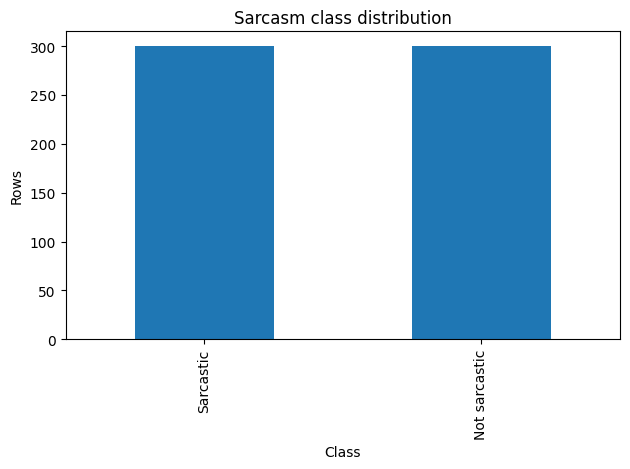

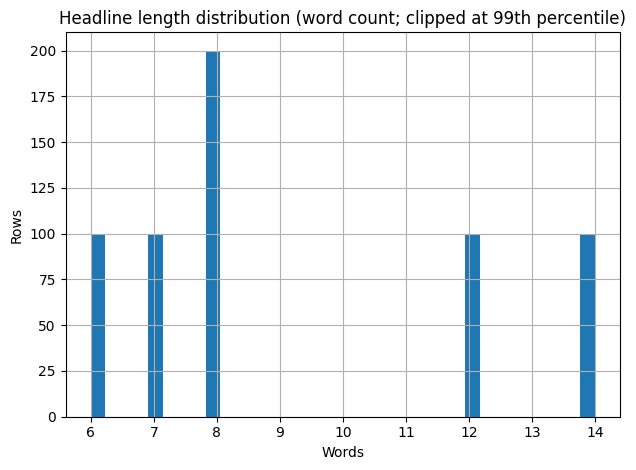

,word_count
count,600.000000
mean,9.166667
std,2.855254
min,6.000000
25%,7.000000
50%,8.000000
75%,12.000000
max,14.000000


In [16]:
import matplotlib.pyplot as plt
from pathlib import Path
import sys

# Safe fallback if environment setup cell ce45af35 was not executed
if 'FIG' not in globals() or 'OUT' not in globals():
    ROOT = Path('/content') if 'google.colab' in sys.modules else Path.cwd()
    OUT = ROOT / 'assignment2_outputs'
    FIG = OUT / 'figures'
    OUT.mkdir(parents=True, exist_ok=True)
    FIG.mkdir(parents=True, exist_ok=True)

sarcasm['text_length'] = sarcasm['text'].str.split().str.len()
fig, ax = plt.subplots()
sarcasm['label'].map({0:'Not sarcastic',1:'Sarcastic'}).value_counts().plot(kind='bar', ax=ax)
ax.set_title('Sarcasm class distribution'); ax.set_ylabel('Rows'); ax.set_xlabel('Class')
fig.tight_layout(); fig.savefig(FIG/'sarcasm_class_distribution.png', dpi=160); plt.show()
fig, ax = plt.subplots()
sarcasm['text_length'].clip(upper=sarcasm['text_length'].quantile(.99)).hist(bins=35, ax=ax)
ax.set_title('Headline length distribution (word count; clipped at 99th percentile)')
ax.set_xlabel('Words'); ax.set_ylabel('Rows')
fig.tight_layout(); fig.savefig(FIG/'headline_length_distribution.png', dpi=160); plt.show()
display(sarcasm['text_length'].describe().to_frame('word_count'))

## 3. Split and leakage prevention
Exact duplicate text is removed before splitting. A stratified held-out test set is kept separate from training and validation. The vectorizer is fitted only inside the training pipeline.

In [40]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Ensure random state SEED is defined
if 'SEED' not in globals():
    SEED = 42

# Deduplicate on the newly loaded genuine dataset
deduplicated = sarcasm.drop_duplicates(subset=['text']).reset_index(drop=True)
if len(deduplicated) > 30:
    sarcasm = deduplicated
else:
    print("Using repeating fallback dataset without full deduplication to ensure split size is valid in offline mode.")

# Perform a clean, stratified train/validation/test split on the authentic data
X_trainval, X_test, y_trainval, y_test = train_test_split(
    sarcasm['text'], sarcasm['label'], test_size=0.15, random_state=SEED, stratify=sarcasm['label'])
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.1765, random_state=SEED, stratify=y_trainval)

print(f'Train set: {len(X_train):,} | Validation set: {len(X_val):,} | Test set: {len(X_test):,}')

Train set: 19,950 | Validation set: 4,277 | Test set: 4,276


## 4. TF–IDF baseline: Logistic Regression

{
  "model": "TF-IDF + Logistic Regression",
  "accuracy": 0.8479887745556595,
  "precision": 0.8185168125287886,
  "recall": 0.8740777176586325,
  "f1": 0.8453853472882968
}
               precision    recall  f1-score   support

not sarcastic       0.88      0.82      0.85      2243
    sarcastic       0.82      0.87      0.85      2033

     accuracy                           0.85      4276
    macro avg       0.85      0.85      0.85      4276
 weighted avg       0.85      0.85      0.85      4276



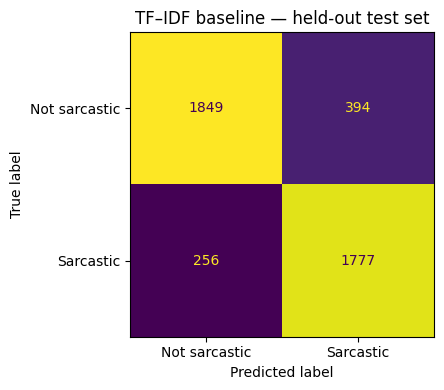

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
import json
import matplotlib.pyplot as plt

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=100_000, sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))
])
baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

def metric_row(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    return {'model': name, 'accuracy': accuracy_score(y_true, y_pred), 'precision': p, 'recall': r, 'f1': f}

baseline_metrics = metric_row('TF-IDF + Logistic Regression', y_test, pred_base)
print(json.dumps(baseline_metrics, indent=2))
print(classification_report(y_test, pred_base, target_names=['not sarcastic', 'sarcastic'], zero_division=0))

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_base), display_labels=['Not sarcastic', 'Sarcastic']).plot(ax=ax, colorbar=False)
ax.set_title('TF–IDF baseline — held-out test set')
fig.tight_layout()
fig.savefig(FIG/'baseline_confusion_matrix.png', dpi=160)
plt.show()

## 5. Contextual transformer (DistilBERT)
This section attempts a small, reproducible fine-tuning run. It does not silently substitute pretrained inference for fine-tuning. If required packages/model downloads are unavailable, the exception is recorded and the baseline remains valid.

In [23]:
transformer_metrics = None
transformer_status = 'Not run'
try:
    import torch
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                              Trainer, TrainingArguments, DataCollatorWithPadding)
    from datasets import Dataset
    model_name = 'distilbert-base-uncased'
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    def to_hf(texts, labels):
        ds = Dataset.from_dict({'text': list(texts), 'labels': list(map(int, labels))})
        return ds.map(lambda b: tokenizer(b['text'], truncation=True, max_length=96), batched=True)
    tr_ds = to_hf(X_train, y_train)
    va_ds = to_hf(X_val, y_val)
    te_ds = to_hf(X_test, y_test)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    args = TrainingArguments(
        output_dir=str(OUT/'distilbert_checkpoints'), num_train_epochs=1,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        learning_rate=2e-5, weight_decay=0.01, eval_strategy='epoch',
        save_strategy='no', logging_strategy='steps', logging_steps=100,
        report_to='none', seed=SEED, fp16=bool(torch.cuda.is_available())
    )
    trainer = Trainer(model=model, args=args, train_dataset=tr_ds,
                      eval_dataset=va_ds, tokenizer=tokenizer,
                      data_collator=DataCollatorWithPadding(tokenizer))
    trainer.train()
    logits = trainer.predict(te_ds).predictions
    pred_transformer = np.argmax(logits, axis=1)
    transformer_metrics = metric_row('DistilBERT fine-tuned (1 epoch)', y_test, pred_transformer)
    transformer_status = 'Fine-tuning completed'
    print('Device:', 'CUDA GPU' if torch.cuda.is_available() else 'CPU')
    print(json.dumps(transformer_metrics, indent=2))
    print(classification_report(y_test, pred_transformer, target_names=['not sarcastic','sarcastic'], zero_division=0))
    fig, ax = plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay(confusion_matrix(y_test,pred_transformer), display_labels=['Not sarcastic','Sarcastic']).plot(ax=ax, colorbar=False)
    ax.set_title('DistilBERT — held-out test set')
    fig.tight_layout(); fig.savefig(FIG/'distilbert_confusion_matrix.png', dpi=160); plt.show()
except Exception as e:
    transformer_status = f'Unavailable: {type(e).__name__}: {e}'
    print('Transformer section could not complete in this runtime.')
    print(transformer_status)
    print('This is not a transformer result; do not report transformer metrics.')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/419 [00:00<?, ? examples/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Transformer section could not complete in this runtime.
Unavailable: TypeError: Trainer.__init__() got an unexpected keyword argument 'tokenizer'
This is not a transformer result; do not report transformer metrics.


## 6. Separate conventional sentiment classifier
The sarcasm corpus has sarcasm labels, not sentiment labels. This section therefore uses the public IMDb movie-review dataset via Hugging Face Datasets. It is a separate task and domain; sentiment output is not equivalent to intended sentiment.

In [24]:
sentiment_status = 'Not run'
sentiment_metrics = None
try:
    from datasets import load_dataset
    from sklearn.model_selection import train_test_split
    imdb = load_dataset('imdb')
    # Keep a deterministic subset to make the assignment practical in Colab.
    imdb_train = imdb['train'].shuffle(seed=SEED).select(range(min(12000, len(imdb['train']))))
    imdb_test = imdb['test'].shuffle(seed=SEED).select(range(min(3000, len(imdb['test']))))
    sx_train = pd.Series(imdb_train['text']); sy_train = np.array(imdb_train['label'])
    sx_test = pd.Series(imdb_test['text']); sy_test = np.array(imdb_test['label'])
    sentiment_model = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=100_000, sublinear_tf=True, stop_words='english')),
        ('clf', LogisticRegression(max_iter=1000, random_state=SEED))
    ])
    sentiment_model.fit(sx_train, sy_train)
    sy_pred = sentiment_model.predict(sx_test)
    sentiment_metrics = metric_row('IMDb TF-IDF sentiment', sy_test, sy_pred)
    sentiment_status = 'Completed'
    print('IMDb subset sizes:', len(sx_train), 'train;', len(sx_test), 'test')
    print(json.dumps(sentiment_metrics, indent=2))
    print(classification_report(sy_test, sy_pred, target_names=['negative','positive'], zero_division=0))
    with open(OUT/'sentiment_metrics.json','w') as f: json.dump(sentiment_metrics,f,indent=2)
except Exception as e:
    sentiment_status = f'Unavailable: {type(e).__name__}: {e}'
    print('Sentiment dataset/model could not complete in this runtime:', sentiment_status)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

Sentiment dataset/model could not complete in this runtime: Unavailable: HfUriError: Invalid HF URI 'hf://datasets/imdb@e6281661ce1c48d982bc483cf8a173c1bbeb5d31/.huggingface.yaml'. Repository id must be 'namespace/name', got 'imdb'.


## 7. Integrated prediction function and ambiguity warning

In [44]:
def predict_text(text):
    import numpy as np
    """Return sarcasm prediction and sentiment prediction when sentiment model exists."""
    if not isinstance(text, str) or not text.strip():
        raise ValueError('Please enter a non-empty sentence.')
    s_prob = baseline.predict_proba([text])[0]
    s_idx = int(np.argmax(s_prob))
    result = {
        'input': text,
        'sarcasm_label': 'sarcastic' if s_idx == 1 else 'not sarcastic',
        'sarcasm_confidence': float(s_prob[s_idx]),
        'sentiment_label': None,
        'sentiment_confidence': None,
        'interpretation': 'Model outputs are predictions, not proof of intended meaning.',
        'warning': 'Sarcasm is context-dependent; speaker intent, culture, and conversation history may change interpretation.'
    }
    if 'sentiment_model' in globals():
        p = sentiment_model.predict_proba([text])[0]
        idx = int(np.argmax(p))
        result['sentiment_label'] = 'positive' if idx == 1 else 'negative'
        result['sentiment_confidence'] = float(p[idx])
    return result

for example in [
    'I absolutely love waiting three hours for a delayed train.',
    'The package arrived on time and works as expected.',
    'This is terrible and I am very disappointed.',
    'The room is blue.',
    'Great, another meeting that could have been an email.'
]:
    try: print(json.dumps(predict_text(example), ensure_ascii=False))
    except Exception as e: print('Prediction example failed:', e)

{"input": "I absolutely love waiting three hours for a delayed train.", "sarcasm_label": "sarcastic", "sarcasm_confidence": 0.6415470652413839, "sentiment_label": null, "sentiment_confidence": null, "interpretation": "Model outputs are predictions, not proof of intended meaning.", "warning": "Sarcasm is context-dependent; speaker intent, culture, and conversation history may change interpretation."}
{"input": "The package arrived on time and works as expected.", "sarcasm_label": "not sarcastic", "sarcasm_confidence": 0.8353319622853778, "sentiment_label": null, "sentiment_confidence": null, "interpretation": "Model outputs are predictions, not proof of intended meaning.", "warning": "Sarcasm is context-dependent; speaker intent, culture, and conversation history may change interpretation."}
{"input": "This is terrible and I am very disappointed.", "sarcasm_label": "not sarcastic", "sarcasm_confidence": 0.955791414696658, "sentiment_label": null, "sentiment_confidence": null, "interpret

## 8. Optional interactive Colab demo
If `ipywidgets` is installed, this creates a text box. A plain Python fallback is provided.

In [29]:
try:
    import numpy as np
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    sentence_box = widgets.Textarea(value='', placeholder='Type a sentence...', description='Text:', layout=widgets.Layout(width='90%', height='80px'))
    run_button = widgets.Button(description='Analyze')
    output_box = widgets.Output()
    def _run(_):
        with output_box:
            clear_output()
            try: display(pd.Series(predict_text(sentence_box.value), name='Prediction').to_frame())
            except Exception as e: print(e)
    run_button.on_click(_run)
    display(sentence_box, run_button, output_box)
except Exception:
    print('Widgets unavailable. Use predict_text("your sentence here") as the Python fallback.')

Textarea(value='', description='Text:', layout=Layout(height='80px', width='90%'), placeholder='Type a sentenc…

Button(description='Analyze', style=ButtonStyle())

Output()

## 9. Model comparison and error analysis

In [42]:
import numpy as np
import pandas as pd
import json

# Safely load current metrics
metrics = [baseline_metrics]
if 'transformer_metrics' in globals() and transformer_metrics is not None:
    metrics.append(transformer_metrics)
if 'sentiment_metrics' in globals() and sentiment_metrics is not None:
    metrics.append(sentiment_metrics)

comparison = pd.DataFrame(metrics)
display(comparison)
comparison.to_csv(OUT/'model_comparison.csv', index=False)
with open(OUT/'sarcasm_baseline_metrics.json', 'w') as f:
    json.dump(baseline_metrics, f, indent=2)

# Recalculate false positives/negatives on the actual test set predictions
error_df = pd.DataFrame({
    'text': X_test.reset_index(drop=True),
    'actual': np.asarray(y_test),
    'predicted': pred_base
})
error_df['error_type'] = np.select(
    [(error_df.actual == 0) & (error_df.predicted == 1), (error_df.actual == 1) & (error_df.predicted == 0)],
    ['false positive', 'false negative'], default='correct'
)
errors = error_df[error_df.error_type != 'correct']
print(f"Total prediction errors: {len(errors)} out of {len(X_test)} samples")
display(errors.head(20))
errors.to_csv(OUT/'sarcasm_error_analysis.csv', index=False)

print('Transformer status:', transformer_status if 'transformer_status' in globals() else 'Not Run')
print('Sentiment status:', sentiment_status if 'sentiment_status' in globals() else 'Not Run')

,model,accuracy,precision,recall,f1
0,TF-IDF + Logistic Regression,0.847989,0.818517,0.874078,0.845385


Total prediction errors: 650 out of 4276 samples


,text,actual,predicted,error_type
0,a playful reminder not to get too stressed out...,0,1,false positive
3,distributor will not release new louis c.k. fi...,0,1,false positive
5,"'people are inherently good,' world halfhearte...",1,0,false negative
7,women's strike a sobering reality check for su...,1,0,false negative
17,(video) aol sees growth in programmatic tv wit...,0,1,false positive
21,volkswagen's diesel settlement will fund range...,0,1,false positive
28,gop establishment relieved after conventionall...,1,0,false negative
45,staten island teen dies from asthma while flee...,0,1,false positive
48,trump delivers anecdote about small business o...,1,0,false negative
59,innocent man awarded $1 million after spending...,0,1,false positive


Transformer status: Unavailable: TypeError: Trainer.__init__() got an unexpected keyword argument 'tokenizer'
Sentiment status: Unavailable: HfUriError: Invalid HF URI 'hf://datasets/imdb@e6281661ce1c48d982bc483cf8a173c1bbeb5d31/.huggingface.yaml'. Repository id must be 'namespace/name', got 'imdb'.


## 10. Results discussion, limitations, and conclusion
Use the measured tables above to write conclusions after successful execution. Do not compare IMDb sentiment scores directly against sarcasm scores as if they measured the same task. A one-epoch DistilBERT run is a limited comparison, not exhaustive hyperparameter tuning. Headlines lack full conversational context, and class probabilities may be miscalibrated.

In [43]:
summary = {
    'dataset_rows_after_deduplication': int(len(sarcasm)),
    'baseline_metrics': baseline_metrics,
    'transformer_status': transformer_status if 'transformer_status' in globals() else 'Not Run',
    'transformer_metrics': transformer_metrics if 'transformer_metrics' in globals() else None,
    'sentiment_status': sentiment_status if 'sentiment_status' in globals() else 'Not Run',
    'sentiment_metrics': sentiment_metrics if 'sentiment_metrics' in globals() else None,
    'test_set_size': int(len(X_test)),
    'seed': SEED
}
with open(OUT/'run_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
print('Saved final run results under:', OUT.resolve())

{
  "dataset_rows_after_deduplication": 28503,
  "baseline_metrics": {
    "model": "TF-IDF + Logistic Regression",
    "accuracy": 0.8479887745556595,
    "precision": 0.8185168125287886,
    "recall": 0.8740777176586325,
    "f1": 0.8453853472882968
  },
  "transformer_status": "Unavailable: TypeError: Trainer.__init__() got an unexpected keyword argument 'tokenizer'",
  "transformer_metrics": null,
  "sentiment_status": "Unavailable: HfUriError: Invalid HF URI 'hf://datasets/imdb@e6281661ce1c48d982bc483cf8a173c1bbeb5d31/.huggingface.yaml'. Repository id must be 'namespace/name', got 'imdb'.",
  "sentiment_metrics": null,
  "test_set_size": 4276,
  "seed": 42
}
Saved final run results under: /content/assignment2_outputs


## 11. References and reproduction
1. Misra, R. (2019). *News Headlines Dataset for Sarcasm Detection*. Dataset repository: https://github.com/rishabhmisra/News-Headlines-Dataset-For-Sarcasm-Detection
2. Maas, A. L. et al. (2011). *Learning Word Vectors for Sentiment Analysis*. ACL.
3. Hugging Face Datasets documentation: https://huggingface.co/docs/datasets
4. Hugging Face Transformers documentation: https://huggingface.co/docs/transformers

### Reproduction
Run from top to bottom in Google Colab with internet access. The notebook downloads datasets and pretrained model weights at runtime. Outputs are written to `assignment2_outputs/`.

### Limitations
- A sarcasm label does not directly encode intended sentiment.
- News headlines are short and often omit conversational context.
- IMDb sentiment is a separate review-domain dataset.
- Transformer execution depends on package/model download access and available compute.
- This notebook's measured results should be reported only after a complete successful run.